In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (AgglomerativeClustering,KMeans)
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8,5)


In [ ]:
df = pd.read_csv("Wholesale customers data.csv")

In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.shape

(440, 8)

In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [ ]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [ ]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
features = [
    'Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'
]

In [ ]:
X = df[features].copy()
display(X.head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
print("Number of records used for clustering: ", len(X))

Number of records used for clustering:  440


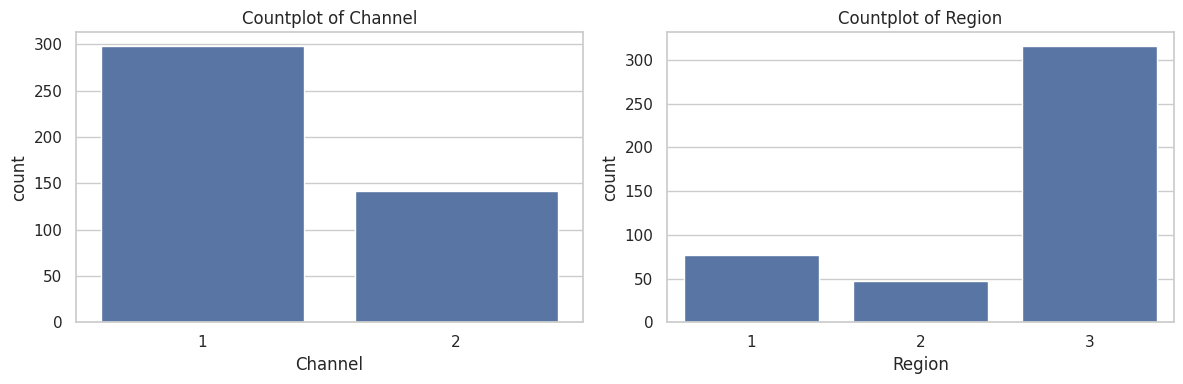

In [ ]:

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Channel')
plt.title('Countplot of Channel')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Region')
plt.title('Countplot of Region')
plt.tight_layout()
plt.show()


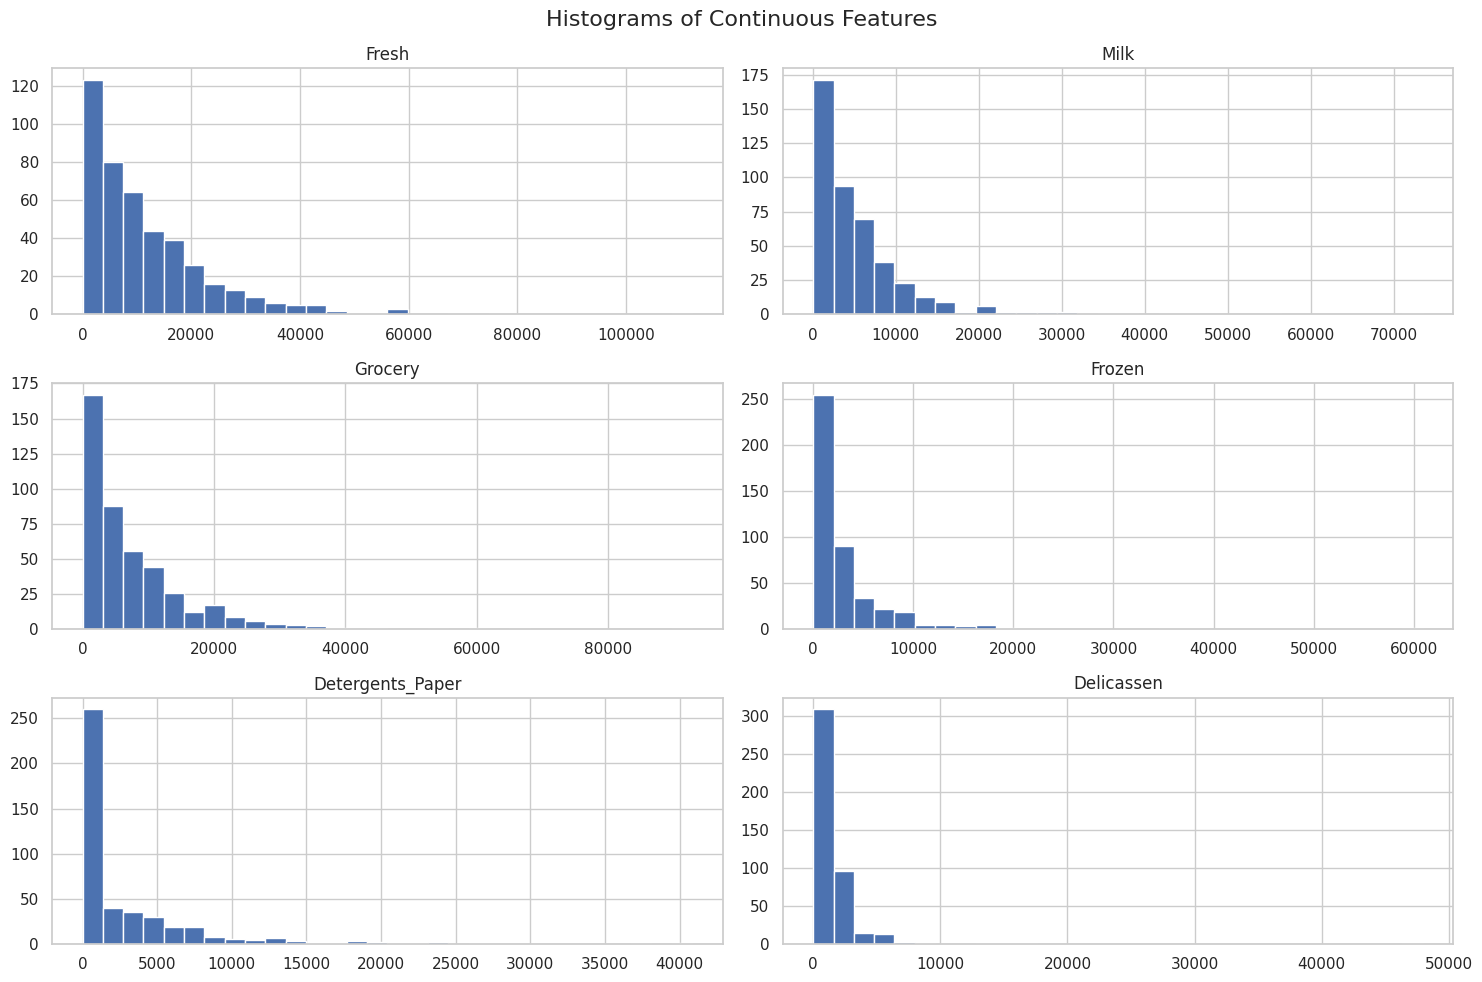

In [ ]:

continuous_features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
df[continuous_features].hist(bins=30, figsize=(15, 10))
plt.suptitle('Histograms of Continuous Features', fontsize=16)
plt.tight_layout()
plt.show()

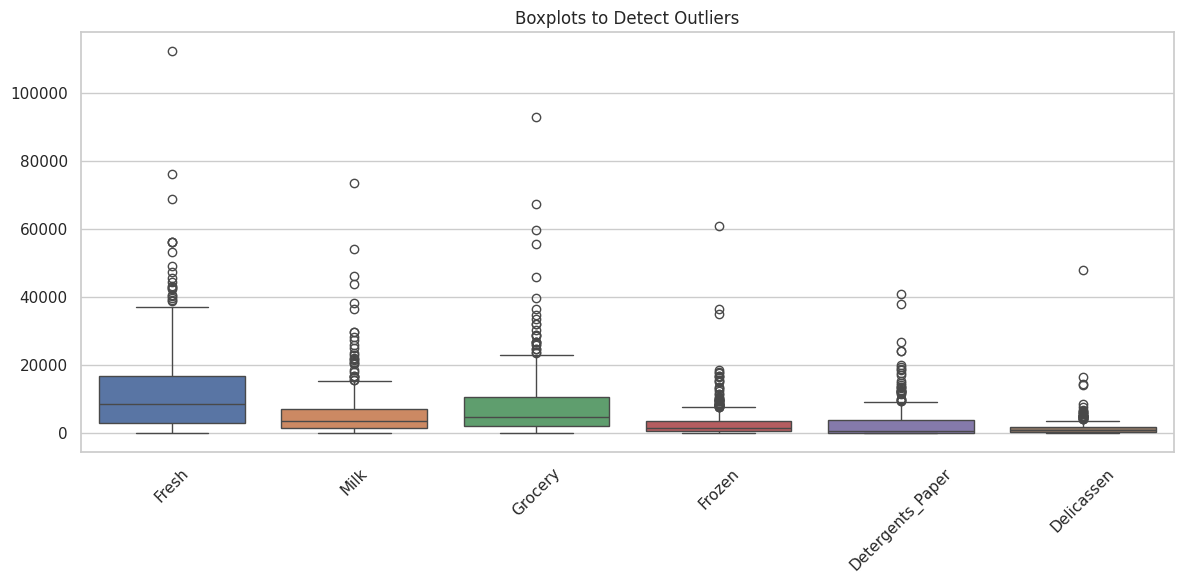

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[continuous_features])
plt.title('Boxplots to Detect Outliers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


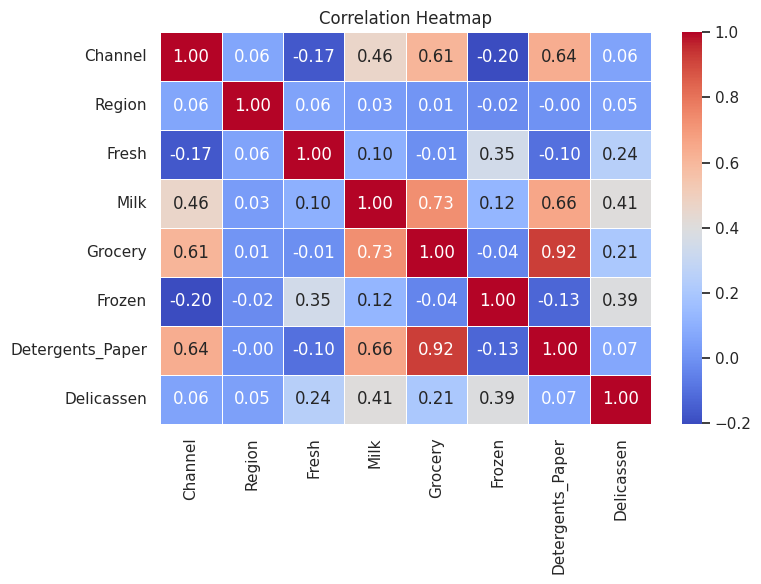

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

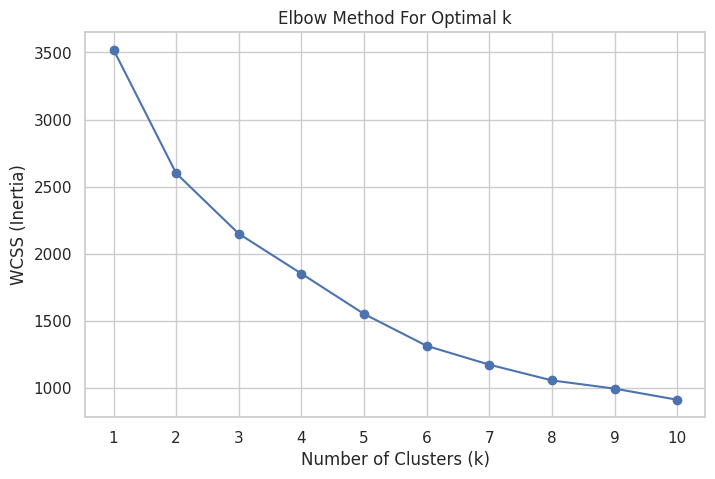

In [ ]:
from sklearn.cluster import KMeans

wcss = []
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(cluster_range, wcss, marker='o', linestyle='-', color='b')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"For n_clusters = {k}, the average silhouette_score is : {score:.4f}")

silhouette_table = pd.DataFrame({'n_clusters': k_range, 'silhouette_score': silhouette_scores})
display(silhouette_table)

For n_clusters = 2, the average silhouette_score is : 0.3734
For n_clusters = 3, the average silhouette_score is : 0.3568
For n_clusters = 4, the average silhouette_score is : 0.3482
For n_clusters = 5, the average silhouette_score is : 0.3529
For n_clusters = 6, the average silhouette_score is : 0.3526
For n_clusters = 7, the average silhouette_score is : 0.3638
For n_clusters = 8, the average silhouette_score is : 0.3743
For n_clusters = 9, the average silhouette_score is : 0.3081
For n_clusters = 10, the average silhouette_score is : 0.3310


,n_clusters,silhouette_score
0,2,0.373374
1,3,0.356769
2,4,0.348195
3,5,0.352924
4,6,0.352584
5,7,0.363832
6,8,0.374265
7,9,0.308055
8,10,0.330979


In [ ]:
suggested_k = int(
    silhouette_table.loc[silhouette_table['silhouette_score'].idxmax(), 'n_clusters']
)
print("K suggested by the highest silhouette score", suggested_k)

K suggested by the highest silhouette score 8


In [ ]:
K = suggested_k

kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [ ]:
df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels
print("K-Means Clustering Completed.")
print("\nNumber of customers in each cluster: ")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nSample records with cluster labels: ")
display(df_kmeans.head())

K-Means Clustering Completed.

Number of customers in each cluster: 
KMeans_Cluster
0    201
1     92
2     37
3     61
4      2
5      5
6      1
7     41
Name: count, dtype: int64

Sample records with cluster labels: 


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,1


In [ ]:
hierarchial_model = AgglomerativeClustering(
    n_clusters = K,
    linkage = "ward",
    metric = "euclidean"
)
hierarchical_labels = hierarchial_model.fit_predict(X_scaled)

In [ ]:
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluser"] = hierarchical_labels

print("Hierarchical Clustering Completed.")
print("\nNumber of customers in each cluster: ")
print(df_hierarchical["Hierarchical_Cluser"].value_counts().sort_index())

print("\nSample records with cluster labels: ")
display(df_hierarchical.head())

Hierarchical Clustering Completed.

Number of customers in each cluster: 
Hierarchical_Cluser
0    205
1      5
2     13
3      2
4     78
5     40
6     96
7      1
Name: count, dtype: int64

Sample records with cluster labels: 


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluser
0,2,3,12669,9656,7561,214,2674,1338,6
1,2,3,7057,9810,9568,1762,3293,1776,6
2,2,3,6353,8808,7684,2405,3516,7844,6
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,6


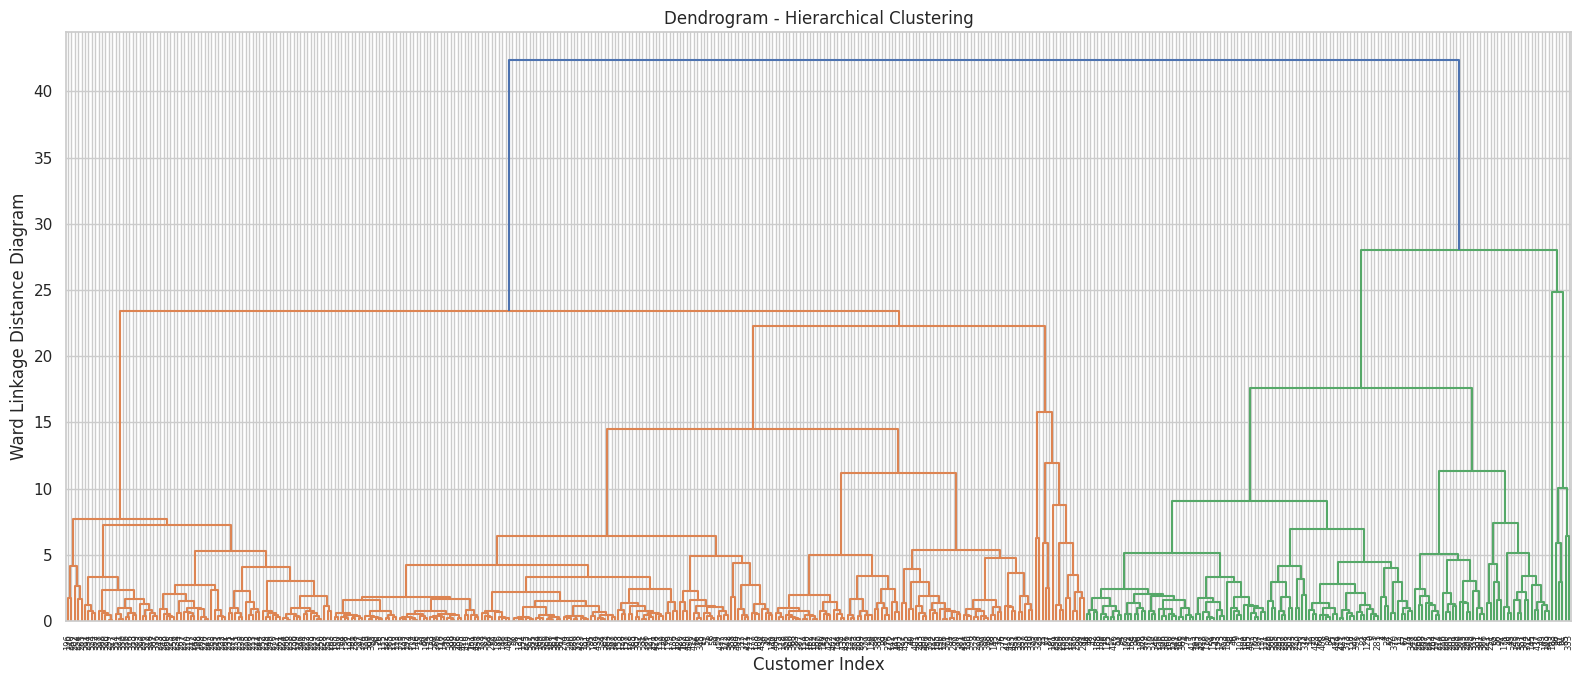

In [ ]:
Z = linkage(X_scaled, method = "ward", metric = "euclidean")

plt.figure(figsize=(16,7))
dendrogram(Z, leaf_rotation = 90, leaf_font_size = 6)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance Diagram")
plt.tight_layout()

plt.show()

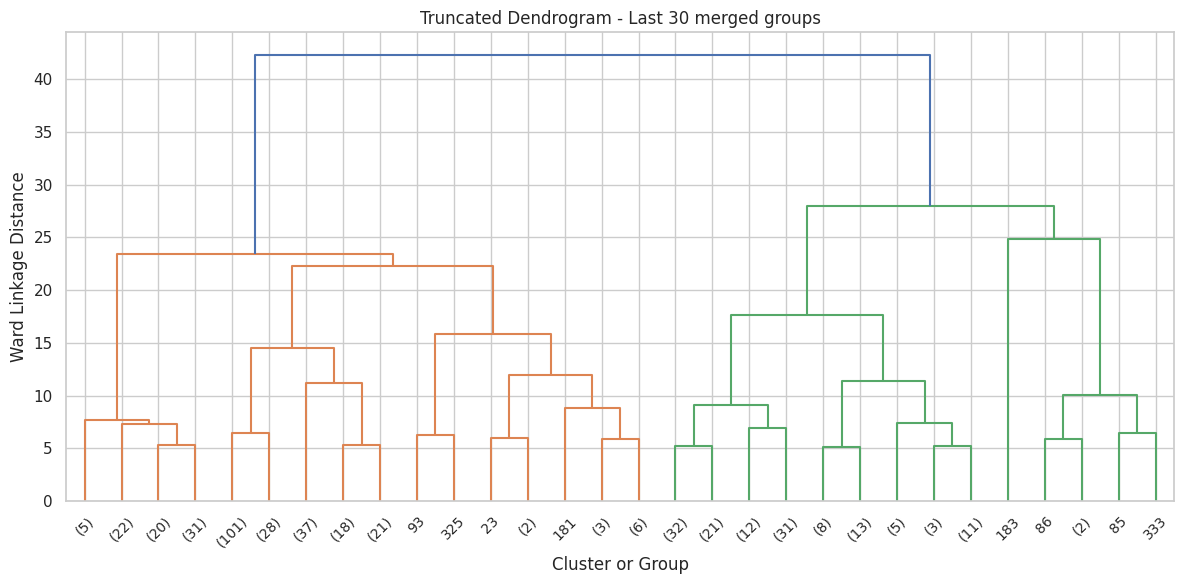

In [ ]:
plt.figure(figsize=(12,6))
dendrogram(Z, truncate_mode = "lastp", p = 30, show_leaf_counts=True, leaf_rotation = 45)

plt.title("Truncated Dendrogram - Last 30 merged groups")
plt.xlabel("Cluster or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()

plt.show()

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by the 2 PCA components: ",
    round(pca.explained_variance_ratio_.sum()*100,2),
    "%"
)

plot_df = pd.DataFrame({"PC1": X_pca[:,0], "PC2": X_pca[:,1],
  "KMeans_Cluster": kmeans_labels.astype(str),
  "Hierarchical_Cluster": hierarchical_labels.astype(str)})

Variance explained by the 2 PCA components:  61.12 %


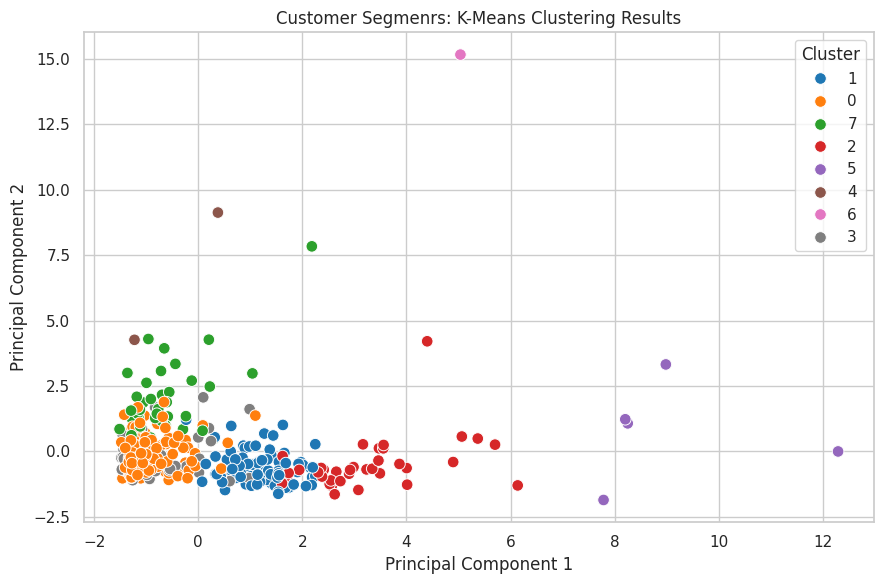

In [ ]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="KMeans_Cluster", palette = "tab10",s=70)

plt.title("Customer Segmenrs: K-Means Clustering Results")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

In [ ]:
def evaluate_clustering(X_data, labels, model_name):
  return{
      "Algorithm": model_name,
      "Number of Clusters": len(np.unique(labels)),
      "Silhouette Score": silhouette_score(X_data, labels),
      "Davies-Bouldin Score": davies_bouldin_score(X_data, labels),
      "Calinski-Harabasz Score": calinski_harabasz_score(X_data, labels)
  }


In [ ]:
cluster_sizes = pd.DataFrame({
    "K-Means": df_kmeans["KMeans_Cluster"].value_counts().sort_index(),
    "Hierarchical": df_hierarchical["Hierarchical_Cluser"].value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster Sizes: ")
display(cluster_sizes)

Cluster Sizes: 


,K-Means,Hierarchical
0,201,205
1,92,5
2,37,13
3,61,2
4,2,78
5,5,40
6,1,96
7,41,1


In [ ]:
kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] = kmeans_labels

print("Average Spending Profile of K-Means Clusters: ")
display(kmeans_profile.groupby("Cluster")[features].mean().round(2))


Average Spending Profile of K-Means Clusters: 


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,,,
0,1.00,2.87,8988.70,2796.09,3487.16,2816.39,733.18,1002.09
1,2.00,2.88,8731.82,7392.77,11361.22,1475.26,4698.03,1449.65
2,2.00,2.16,5694.54,15773.59,24499.59,1707.92,11545.19,2463.08
3,1.10,1.00,10095.11,3965.02,4382.66,2816.43,1191.66,1127.75
4,1.00,2.50,22015.50,9937.00,7844.00,47939.00,671.50,4153.50
5,2.00,2.80,25603.00,43460.60,61472.20,2636.00,29974.20,2708.80
6,1.00,3.00,36847.00,43950.00,20170.00,36534.00,239.00,47943.00
7,1.05,2.78,39870.29,4916.85,5740.59,6566.93,901.27,2595.95


In [ ]:
cluster_distribution = pd.DataFrame({
    "Customer Count": pd.Series(kmeans_labels).value_counts().sort_index()
})

cluster_distribution["Percentage"] = (cluster_distribution["Customer Count"]/len(df)*100).round(2)

print("K-Means Cluster Distribution: ")
display(cluster_distribution)

K-Means Cluster Distribution: 


,Customer Count,Percentage
0,201,45.68
1,92,20.91
2,37,8.41
3,61,13.86
4,2,0.45
5,5,1.14
6,1,0.23
7,41,9.32


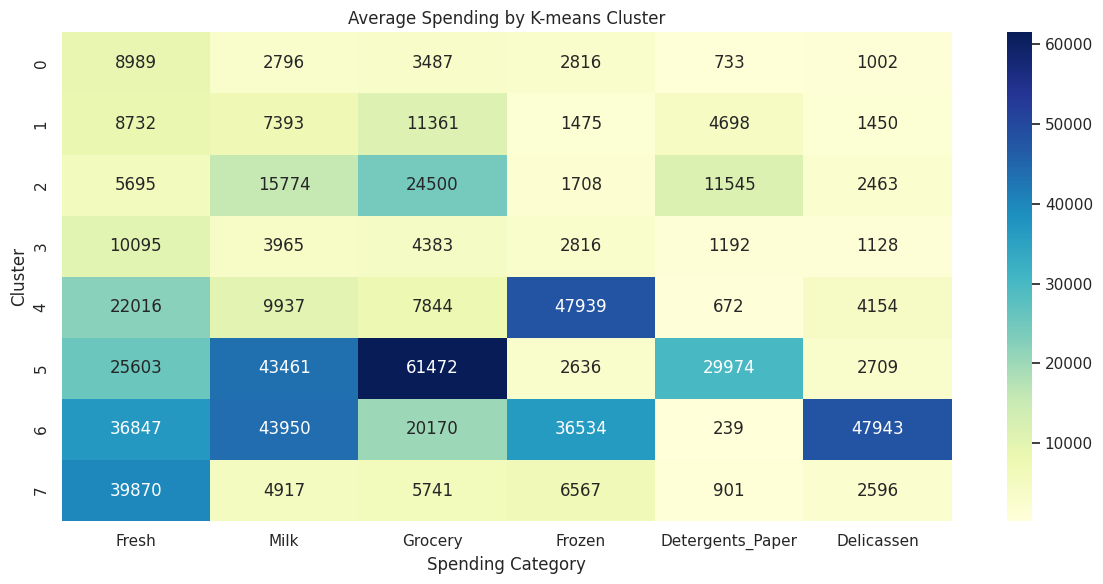

In [ ]:
KMeans_means = kmeans_profile.groupby("Cluster")[continuous_features].mean()

plt.figure(figsize=(12,6))
sns.heatmap(KMeans_means, annot=True, fmt=".0f", cmap="YlGnBu")

plt.title("Average Spending by K-means Cluster")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")
plt.tight_layout()

plt.show()

In [ ]:
channel_mix = pd.crosstab(df["Channel"], kmeans_labels, normalize = "columns")*100
channel_mix.columns = [f"Cluster {c}" for c in channel_mix.columns]
print("Channel composition within each K-Means cluster (%) : ")
display(channel_mix.round(2))

Channel composition within each K-Means cluster (%) : 


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7
Channel,,,,,,,,
1,100.0,0.0,0.0,90.16,100.0,0.0,100.0,95.12
2,0.0,100.0,100.0,9.84,0.0,100.0,0.0,4.88
